# Supplementary Figures S6, S7, S9 and S10

This notebook reproduces the Supplementary Figures:

- Supplementary Fig. S6: correlation between network degree and publication volume (FigSI_CorrDegreePubs)
- Supplementary Fig. S7: probability of an edge type vs publication volume (FigSI_ProbEdgeSignPubs)
- Supplementary Fig. S9: community connection probability over time (FigSI_connectionprob)
- Supplementary Fig. S10: variance inflation factor of the multinomial logit model (FigSI_VIF_multi)

It reads the processed data in the data folder (`path2data`) and can be run on its own.

In [1]:
import os
import json
import gzip
import itertools
from itertools import chain
import pandas as pd
import numpy as np
import networkx as nx

import scipy.sparse as spsparse
import scipy.stats as spstats

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

from vizutils import pvalue2stars, table_row, make_multinomial_latex_table, logistic_coefficient_plot

import pyscisci.all as pyscisci

# set this path to where the OpenAlex database is stored
path2openalex = '/Users/hgt6rn/Documents/DataSets/OpenAlex'

# set this path to where the processed data (Source Data) is stored:
path2sourcedata = "Source Data"
# when the notebook is run from the code folder, the Source Data folder is one level up
if not os.path.exists(path2sourcedata):
    path2sourcedata = os.path.join("..", "Source Data")

# the processed input data are in the data folder, next to the Source Data folder
path2data = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'data')


Please install python-Levenshtein to take full advantage of the NLP tools. 
 pip install python-Levenshtein
Please install sparse_dot_topn to take full advantage of the NLP tools. 
 pip install sparse_dot_topn


/Users/psp2nq/anaconda3/lib/python3.11/site-packages/dask/dataframe/__init__.py:49: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


 # Analysis of the International Recognition Network

In [2]:
# lets focus on the citation without the same organization and self citations

country_auc_df = pd.read_csv(os.path.join(path2data, 'oa_countrycites_nosameorg_auc.csv.gz'))

country_auc_df = country_auc_df[country_auc_df['N']>=50]

country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5)/np.sqrt(country_auc_df['Cov'])
# one-sided test in the direction of the observed preference: H1 is AUC > 0.5 (over-citation)
# when Z > 0, and AUC < 0.5 (under-citation) when Z < 0
country_auc_df['pvalue'] = spstats.norm.sf(np.abs(country_auc_df['Zscore'].values))

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
country_auc_df['Significant'] = country_auc_df.groupby('CitedYear')['pvalue'].transform(reject_holm)

net_auc = country_auc_df[country_auc_df['CitingCountry'] != country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
net_auc = net_auc[net_auc['Significant']]
self_auc = country_auc_df[country_auc_df['CitingCountry'] == country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
self_auc = self_auc[self_auc['Significant']]

syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]

comm2country = {0:['AE', 'BD', 'CN', 'CY', 'DZ', 'EG', 'ID', 'IN', 'IQ', 'IR', 'JO', 'KH', 'KR', 'KW', 'MA', 'MY', 'OM', 'PK', 'QA', 'SA', 'SG', 'TH', 'TN', 'TR', 'TW', 'VN'],
1:['AR', 'BN', 'BO', 'BR', 'BW', 'BY', 'CL', 'CM', 'CO', 'CR', 'GE', 'HK', 'HR', 'LU', 'MZ', 'NC', 'PA', 'PE', 'RU', 'SJ', 'ST', 'UY', 'VE'],
2:['AT', 'BE', 'CA', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IE', 'IL', 'IS', 'IT', 'JP', 'MX', 'NL', 'NO', 'NP', 'NZ', 'PH', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK'],
3:['AU', 'CH', 'GB', 'US'],
4:['BH', 'ET', 'GH', 'KE', 'MW', 'NG', 'TZ', 'UG', 'ZA', 'ZM', 'ZW']}

country2comm = {c:ci for ci,clist in comm2country.items() for c in clist}
poscountrylist = sorted(list(country2comm.keys()))

connected_countries = np.sort(np.unique(net_auc[net_auc['Zscore'] > 0][['CitingCountry', 'CitedCountry']].values.flatten()))

In [3]:
syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]
cumulative_net = net_auc.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')

cumulative_net['SourceCommunity'] = cumulative_net['CitingCountry'].map(country2comm)
cumulative_net['TargetCommunity'] = cumulative_net['CitedCountry'].map(country2comm)
cumulative_net['InterCommunity'] = cumulative_net['SourceCommunity'] != cumulative_net['TargetCommunity']

print(cumulative_net.shape, "edges")
cum_connected_countries = np.sort(np.unique(cumulative_net[['CitingCountry', 'CitedCountry']].values.flatten()))
print(cum_connected_countries.shape, "countries")
pcumnet = cumulative_net[cumulative_net['Zscore'] > 0]
print(pcumnet.shape, "positive edges")
print(pcumnet['CitedCountry'].value_counts())
ncumnet = cumulative_net[cumulative_net['Zscore'] < 0]
print(ncumnet.shape, "negative edges")
print(ncumnet['CitedCountry'].value_counts())

(2007, 12) edges
(147,) countries
(536, 12) positive edges
CitedCountry
CH    36
GB    31
NL    22
DE    22
BE    20
      ..
RU     1
CR     1
HR     1
PE     1
MA     1
Name: count, Length: 81, dtype: int64
(1471, 12) negative edges
CitedCountry
CN    86
JP    63
IR    48
BR    45
TR    45
      ..
CG     1
TJ     1
PH     1
HK     1
GD     1
Name: count, Length: 126, dtype: int64


## relationship between Degree and Productivity

In [4]:
countryprod = pd.read_csv(os.path.join(path2data, 'oa_country_productivity.csv'))
syear = 1990
eyear = 2017

countryprod = countryprod[countryprod['Year'] >= syear]
countryprod = countryprod[countryprod['Year'] <= eyear].reset_index(drop=True)
print(countryprod.shape)

(5869, 5)


In [5]:
deg_table = cumulative_net[cumulative_net['Zscore'] > 0].groupby('CitedCountry', as_index=False)['CitingCountry'].nunique()
deg_table = deg_table.rename(columns={'CitedCountry':'Country', 'CitingCountry':'Pos. In Deg'})

deg_table2 = cumulative_net[cumulative_net['Zscore'] > 0].groupby('CitingCountry', as_index=False)['CitedCountry'].nunique()
deg_table2 = deg_table2.rename(columns={'CitingCountry':'Country', 'CitedCountry':'Pos. Out Deg'})
deg_table = deg_table.merge(deg_table2, how='outer')

deg_table3 = cumulative_net[cumulative_net['Zscore'] < 0].groupby('CitedCountry', as_index=False)['CitingCountry'].nunique()
deg_table3 = deg_table3.rename(columns={'CitedCountry':'Country', 'CitingCountry':'Neg. In Deg'})
deg_table = deg_table.merge(deg_table3, how='outer')

deg_table4 = cumulative_net[cumulative_net['Zscore'] < 0].groupby('CitingCountry', as_index=False)['CitedCountry'].nunique()
deg_table4 = deg_table4.rename(columns={'CitingCountry':'Country', 'CitedCountry':'Neg. Out Deg'})
deg_table = deg_table.merge(deg_table4, how='outer')

deg_table = deg_table.merge(countryprod[countryprod['Year']==2017][['Country', 'NumPub']], how='left')
deg_table = deg_table.fillna(0)

deg_table

,Country,Pos. In Deg,Pos. Out Deg,Neg. In Deg,Neg. Out Deg,NumPub
0,AE,4.0,2.0,9.0,3.0,4997
1,AF,0.0,0.0,0.0,1.0,122
2,AG,0.0,0.0,0.0,1.0,204
3,AL,0.0,0.0,2.0,1.0,572
4,AM,0.0,0.0,2.0,2.0,1055
...,...,...,...,...,...,...
142,XK,0.0,0.0,2.0,2.0,631
143,YE,0.0,0.0,1.0,0.0,403
144,ZA,11.0,14.0,11.0,16.0,23661
145,ZM,1.0,1.0,2.0,4.0,702


## Supplementary Fig. S6: correlation between network degree and publication volume

A 7.301527208769628e-08
B 5.509679462617945e-17
C 6.037579349008934e-14
D 1.572481467618392e-44


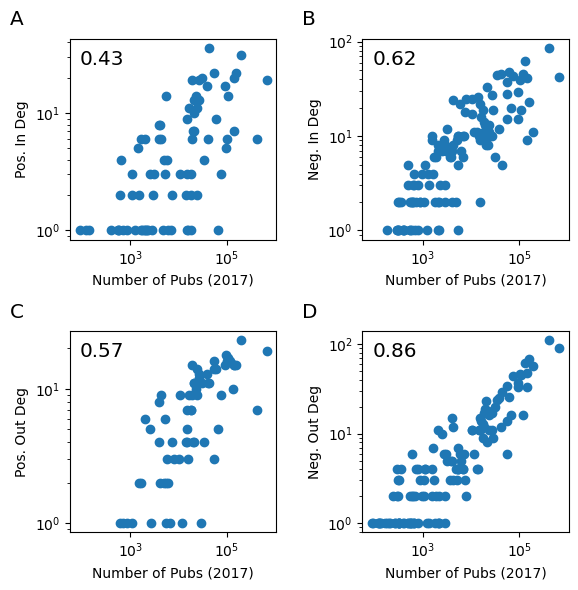

In [6]:
fig, ax = plt.subplots(2,2,figsize=(6,6))

fig_list = [('A', 'Pos. In Deg'), ('B', 'Neg. In Deg'), ('C', 'Pos. Out Deg'), ('D', 'Neg. Out Deg')]
for i, (lbl, yvar) in enumerate(fig_list):
    lax = ax[i//2,i%2]
    lax.scatter(deg_table['NumPub'], deg_table[yvar])
    lax.set_xscale('log')
    lax.set_yscale('log')
    lax.set_ylabel(yvar, fontsize=10)
    lax.set_xlabel('Number of Pubs (2017)', fontsize=10)

    corr = spstats.pearsonr(deg_table['NumPub'], deg_table[yvar])
    #corr = spstats.spearmanr(deg_table['NumPub'], deg_table[yvar])
    corr_str = str(np.round(corr.statistic,2))
    print(lbl, corr.pvalue)
    trans = mtransforms.ScaledTranslation(0.1, -0.3, fig.dpi_scale_trans)
    lax.text(0.0, 1.0, corr_str, transform=lax.transAxes + trans,
                   fontsize='x-large', va='bottom')

    trans = mtransforms.ScaledTranslation(-0.6, 7/72, fig.dpi_scale_trans)
    lax.text(0.0, 1.0, lbl, transform=lax.transAxes + trans,
                   fontsize='x-large', va='bottom')

plt.tight_layout()

plt.show()

## Supplementary Fig. S7: probability of an edge type vs publication volume

D 1.0198994908956393e-26
E 5.21695085423159e-23
F 3.004294068455007e-07
A 0.09193998910002071
B 0.03427050245112352
C 0.37634754760782435


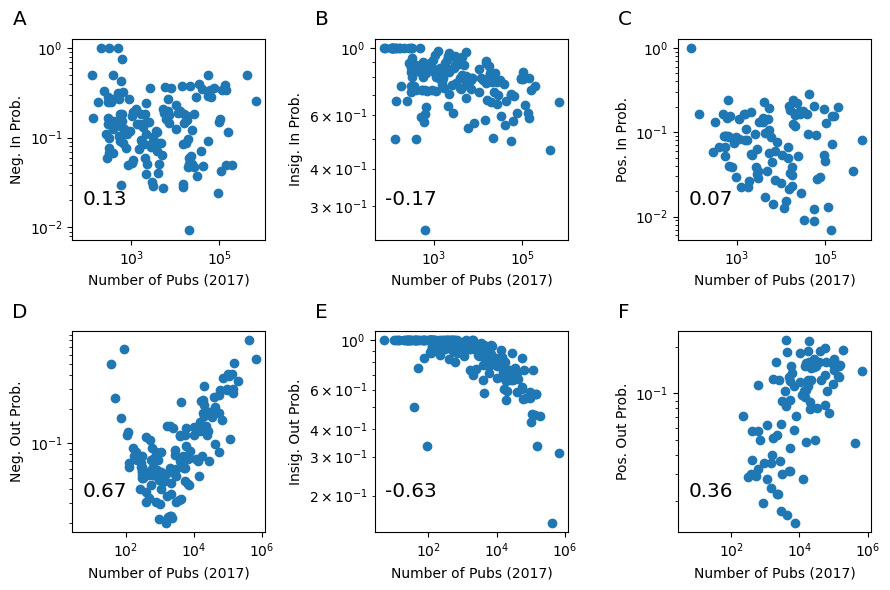

In [7]:
country_auc_df = pd.read_csv(os.path.join(path2data, 'oa_countrycites_nosameorg_auc.csv.gz'))

country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5)/np.sqrt(country_auc_df['Cov'])

n2017 = country_auc_df[country_auc_df['CitedYear'] == 2017]
n2017 = n2017[n2017['N'] >= 50].reset_index(drop=True)
n2017['Sign'] = 0
n2017.loc[n2017['Zscore']<-3, 'Sign'] = -1
n2017.loc[n2017['Zscore']>3, 'Sign'] = 1


prob_edge = []
for c in n2017['CitingCountry'].unique():
    csub = n2017[n2017['CitingCountry']==c]['Sign'].value_counts().to_dict()
    prob_edge.append([c] + [csub.get(v, 0) for v in [-1, 0, 1]])

prob_edge = pd.DataFrame(prob_edge, columns= ['Country', 'Neg. Out Prob.', 'Insig. Out Prob.', 'Pos. Out Prob.']) 
prob_edge['Total'] = prob_edge[['Neg. Out Prob.', 'Insig. Out Prob.', 'Pos. Out Prob.']].sum(axis=1)
for c in ['Neg. Out Prob.', 'Insig. Out Prob.', 'Pos. Out Prob.']:
    prob_edge[c] = prob_edge[c]/prob_edge['Total']

prob_edge = prob_edge.merge(countryprod[countryprod['Year']==2017][['Country', 'NumPub']], how='left')
prob_edge = prob_edge.fillna(0)

fig, ax = plt.subplots(2,3,figsize=(9,6))

fig_list = [('D', 'Neg. Out Prob.'), ('E', 'Insig. Out Prob.'), ('F', 'Pos. Out Prob.')]
for i, (lbl, yvar) in enumerate(fig_list):
    lax = ax[1,i]
    lax.scatter(prob_edge['NumPub'], prob_edge[yvar])
    lax.set_xscale('log')
    lax.set_yscale('log')
    lax.set_ylabel(yvar, fontsize=10)
    lax.set_xlabel('Number of Pubs (2017)', fontsize=10)

    corr = spstats.pearsonr(prob_edge['NumPub'], prob_edge[yvar])
    print(lbl, corr.pvalue)
    #corr = spstats.spearmanr(deg_table['NumPub'], deg_table[yvar])
    corr_str = str(np.round(corr.statistic,2))
    
    trans = mtransforms.ScaledTranslation(0.1, -1.7, fig.dpi_scale_trans)
    lax.text(0.0, 1.0, corr_str, transform=lax.transAxes + trans,
                   fontsize='x-large', va='bottom')

    trans = mtransforms.ScaledTranslation(-0.6, 7/72, fig.dpi_scale_trans)
    lax.text(0.0, 1.0, lbl, transform=lax.transAxes + trans,
                   fontsize='x-large', va='bottom')


# keep the outgoing probabilities (panels D-F) for the Source Data
prob_edge_out = prob_edge.copy()

prob_edge = []
for c in n2017['CitedCountry'].unique():
    csub = n2017[n2017['CitedCountry']==c]['Sign'].value_counts().to_dict()
    prob_edge.append([c] + [csub.get(v, 0) for v in [-1, 0, 1]])

prob_edge = pd.DataFrame(prob_edge, columns= ['Country', 'Neg. In Prob.', 'Insig. In Prob.', 'Pos. In Prob.']) 
prob_edge['Total'] = prob_edge[['Neg. In Prob.', 'Insig. In Prob.', 'Pos. In Prob.']].sum(axis=1)
for c in ['Neg. In Prob.', 'Insig. In Prob.', 'Pos. In Prob.']:
    prob_edge[c] = prob_edge[c]/prob_edge['Total']

prob_edge = prob_edge.merge(countryprod[countryprod['Year']==2017][['Country', 'NumPub']], how='left')
prob_edge = prob_edge.fillna(0)



fig_list = [('A', 'Neg. In Prob.'), ('B', 'Insig. In Prob.'), ('C', 'Pos. In Prob.')]
for i, (lbl, yvar) in enumerate(fig_list):
    lax = ax[0, i]
    lax.scatter(prob_edge['NumPub'], prob_edge[yvar])
    lax.set_xscale('log')
    lax.set_yscale('log')
    lax.set_ylabel(yvar, fontsize=10)
    lax.set_xlabel('Number of Pubs (2017)', fontsize=10)

    corr = spstats.pearsonr(prob_edge['NumPub'], prob_edge[yvar])
    print(lbl, corr.pvalue)
    #corr = spstats.spearmanr(deg_table['NumPub'], deg_table[yvar])
    corr_str = str(np.round(corr.statistic,2))
    
    trans = mtransforms.ScaledTranslation(0.1, -1.7, fig.dpi_scale_trans)
    lax.text(0.0, 1.0, corr_str, transform=lax.transAxes + trans,
                   fontsize='x-large', va='bottom')

    trans = mtransforms.ScaledTranslation(-0.6, 7/72, fig.dpi_scale_trans)
    lax.text(0.0, 1.0, lbl, transform=lax.transAxes + trans,
                   fontsize='x-large', va='bottom')





plt.tight_layout()

plt.show()


## Supplementary Fig. S9: probability of connection within / between communities

In [8]:


renumber_blocks = {3:0, 2:1,1:4,0:2,4:3}

v2com = np.array([renumber_blocks[country2comm[c]] for c in poscountrylist])

fullcnames, fullcsizes = np.unique(v2com, return_counts=True)
print(fullcnames, fullcsizes)
nc = fullcnames.shape[0]

pblock_matrix = np.zeros((eyear - syear + 1, nc,nc))
nblock_matrix = np.zeros((eyear - syear + 1, nc,nc))

for y in range(syear, eyear + 1):
    
    ysub = net_auc[net_auc['CitedYear'] <= y].drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')
    posnet = ysub[ysub['Zscore']>0]
    
    usednodes = np.sort(np.unique(posnet[['CitingCountry', 'CitedCountry']].values.flatten()))
    yv2com = v2com[pyscisci.isin_sorted(connected_countries, usednodes)]
    
    pnet = nx.DiGraph()
    pnet.add_nodes_from(usednodes)
    pnet.add_edges_from([(s, t) for s,t in posnet[['CitingCountry', 'CitedCountry']].values])
    padjmat = nx.to_numpy_array(pnet, nodelist = usednodes)
    
    negnet = ysub[ysub['Zscore']<0]
    nnet = nx.DiGraph()
    nnet.add_nodes_from(usednodes)
    nnet.add_edges_from([(s, t) for s,t in negnet[['CitingCountry', 'CitedCountry']].values])
    nadjmat = nx.to_numpy_array(nnet, nodelist = usednodes)
    
    cnames, csizes = np.unique(yv2com, return_counts=True)
    csizes = dict(zip(cnames, csizes))
    #print(y, yv2com.shape, padjmat.shape, nadjmat.shape)
    #print(cnames, csizes )
    
    for ic in cnames:
        for jc in cnames:
            #denom = csizes[ic]*csizes[jc]
            denom = fullcsizes[ic]*fullcsizes[jc]
            pblock_matrix[y-syear, ic, jc] = padjmat[yv2com==ic][:,yv2com==jc].sum()/denom
            nblock_matrix[y-syear, ic, jc] = nadjmat[yv2com==ic][:,yv2com==jc].sum()/denom

    #print(nblock_matrix)

[0 1 2 3 4] [ 4 29 26 11 23]


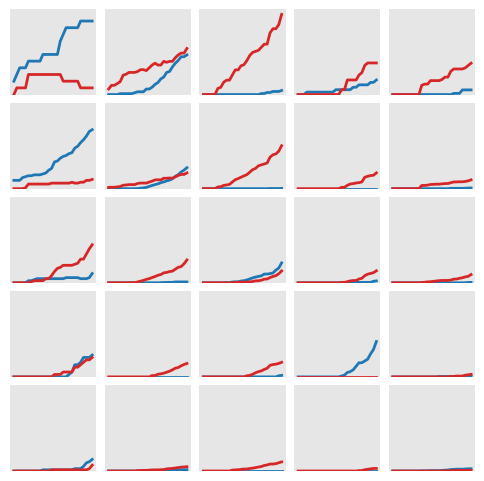

In [9]:


fig = plt.figure(figsize = (6,6))
gs = gridspec.GridSpec(nc,nc)
gs.update(wspace=0.1, hspace=0.1) # set the spacing between axes. 

fontProperties = {'family':'sans-serif','sans-serif':['Helvetica'],
    'weight' : 'normal', 'size' : 12}

for ic in fullcnames:
    for jc in fullcnames:
        
        ax = plt.subplot(gs[ic * nc + jc])
  
        ax.plot(np.arange(1990, 2018), pblock_matrix[:,ic,jc], lw=2)
        ax.plot(np.arange(1990, 2018), nblock_matrix[:,ic,jc], lw=2, color=sns.color_palette()[3])
        
        ax.set_ylim([0, 0.8])
        ax.set_yticks([0,0.75])
        
        ax.tick_params(axis='y', which='major', labelsize=10)
        for tick in ax.get_yticklabels():
            tick.set_fontname("Helvetica") #"Comic Sans MS")
        
        for tick in ax.get_xticklabels():
            tick.set_fontname("Helvetica")
            tick.set_rotation(45)

        #if ~(ic == 0 and jc ==2 or ic==2 and jc ==0):
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        
        ax.set_facecolor('0.9')
        
        if jc > -1:
            ax.set_yticks([])
        
        if ic <6:
            ax.set_xticks([])


plt.show()

## Multinomial link prediction data

The panel data and variables of the multinomial logit model (the models themselves are fitted in 9_GlobalCitationNetwork_TableS6_multinomial).

In [10]:
panel_data = pd.read_csv(os.path.join(path2data, 'link_prediction_panel_data_1990_2017.csv.gz'))


net_panel = panel_data.merge(net_auc.rename(columns={'CitingCountry':'oCountry', 'CitedCountry':'tCountry','CitedYear':'year'}), 
                           how='left', on=['oCountry','tCountry','year'])

net_panel['edge_preference'] = 1 + (net_panel['Zscore'] < 0).astype(int)
net_panel.loc[net_panel['Significant'].isnull(), 'edge_preference'] = 0

net_panel['edge_preference'].unique()

dummy_years=['year_'+str(i) for i in range(syear + 1, eyear + 1)]

all_dummies=['comlang_off','SameContinent']+dummy_years

net_panel_with_dummies = pd.get_dummies(net_panel, columns=['year'], drop_first=True)
net_panel_with_dummies[dummy_years] = net_panel_with_dummies[dummy_years].astype(int)



v1=['oGDP_PCAP','tGDP_PCAP', 'oPop','tPop']
v2=['PhysicalDistance','SameContinent']
v3=['comlang_off','TopicSimilarity']
v4=['cumulative_laws']
v5=['CollabStrength']
v6=['oTopFrac','tTopFrac']


all_model_features = v1 + v2 + v3 + v4 + v5 + v6

exog_var_sets = [v1+dummy_years,v2,v3,v4,v5,v6]
dep_var = "edge_preference"


## Supplementary Fig. S10: multinomial VIF

In [11]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.api import add_constant


# Add a constant (Intercept) for VIF calculation
X = net_panel_with_dummies[v1+v2+v3+v4+v5+v6+dummy_years].dropna().reset_index(drop=True)# Adds an intercept term
X = sm.add_constant(X)

# Compute VIF for each feature
vif_df = pd.DataFrame()
vif_df["Variable"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

namedict = {'const':'Intercept', 'oTopFrac':'Origin top journal fraction', 'tTopFrac':'Target top journal fraction', 'oGDP_PCAP':'Log origin GDP per capita', 'oPop':'Log origin population','tPop':'Log target population',
           'tGDP_PCAP':'Log target GDP per capita', 'PhysicalDistance': 'Physical distance', 'TopicSimilarity':'Field similarity', 
            'tradeflow_baci':'Log trade volume', 'comlang_off':'Same official language', 'CollabStrength':'Log collaboration strength','DemocDis': 'Democracy distance','oDemoc':'Origin democracy','tDemoc':'Target democracy','SameContinent':'Same continent',
           'cumulative_laws':'Bilateral research agreements'}

vif_df.replace(namedict,inplace=True)
vif_plot=vif_df[vif_df['Variable']!='Intercept']



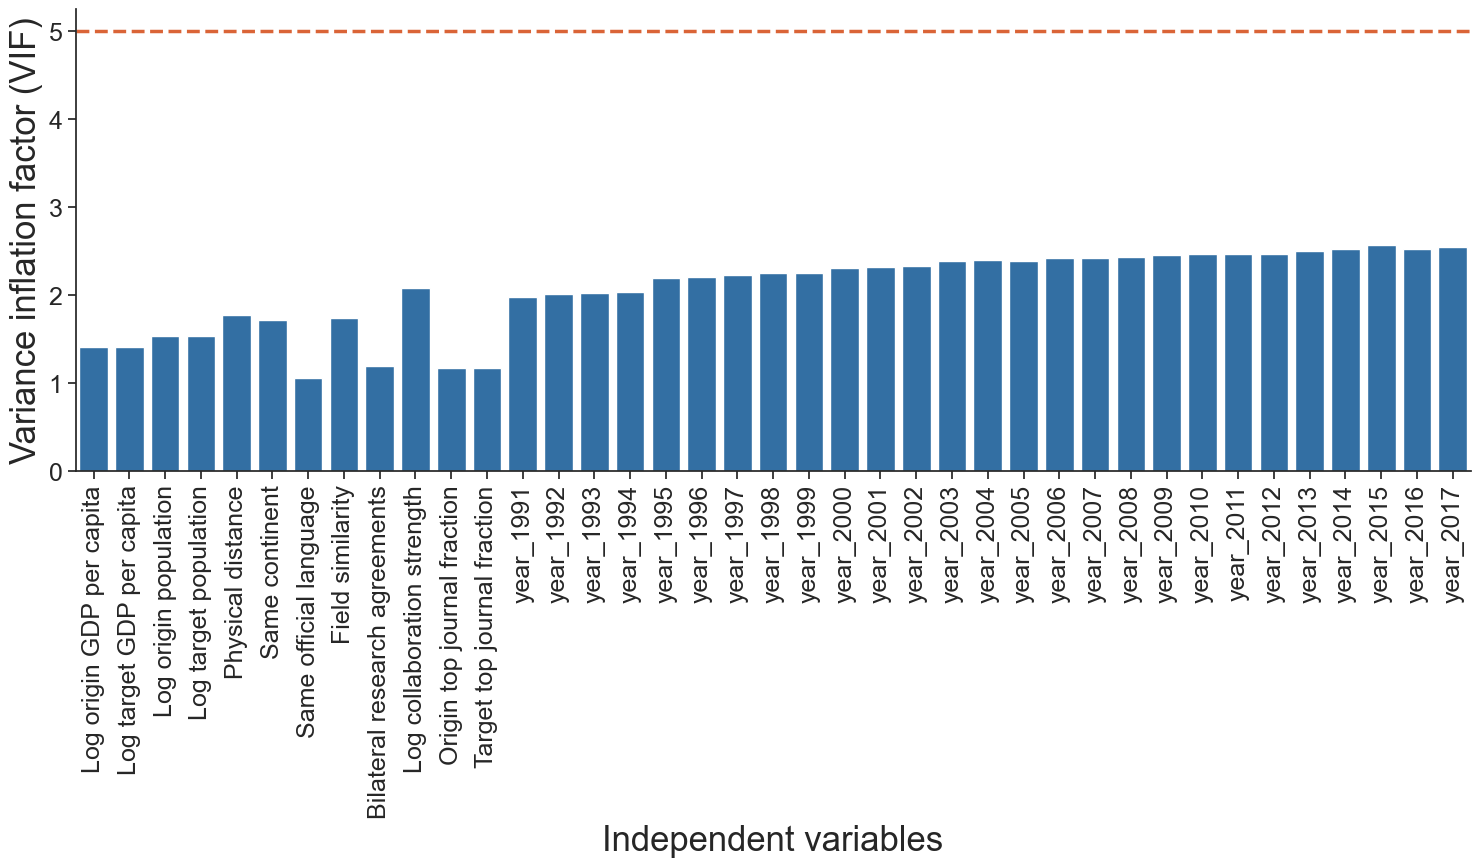

In [12]:
colours=['#8D95A0','#2171b5','#DA6437']

custom_params = {"axes.spines.bottom": True, "axes.spines.right": False, "axes.spines.top": False,
                     "axes.spines.left": True,"ytick.left":True, "xtick.bottom":True}
sns.set_theme(style='ticks', rc=custom_params)


plt.figure(figsize=(18, 6))

ax = sns.barplot(x="Variable", y="VIF", data=vif_plot, 
                     color=colours[1])
    
plt.xlabel("Independent variables", fontsize=25)
plt.ylabel("Variance inflation factor (VIF)", fontsize=25)

plt.xticks(rotation=90, ha='center')

ax.axhline(y=5, color=colours[2],  linestyle='--', lw=2.5)



ax.tick_params(axis='both', which='major', labelsize=18, direction='out',)

plt.show()

## Source Data for Supplementary Figs. S6, S7, S9 and S10

The values plotted in each figure, written to `Source Data/SourceData_FigS6.xlsx`, `SourceData_FigS7.xlsx`, `SourceData_FigS9.xlsx` and `SourceData_FigS10.xlsx`.

In [13]:
from sourcedatautils import write_source_data

s6 = deg_table.rename(columns={'Pos. In Deg':'Positive in-degree', 'Pos. Out Deg':'Positive out-degree',
                               'Neg. In Deg':'Negative in-degree', 'Neg. Out Deg':'Negative out-degree',
                               'NumPub':'Number of publications (2017)'})
write_source_data('SourceData_FigS6.xlsx', 'Supplementary Figure 6: Correlation between network degree and publication volume.',
                  ('Positive and negative in- and out-degree of each country in the cumulative network (1990-2017) and its '
                   'number of publications in 2017.'),
                  [('S6', 'Degree and publication volume of each country.', s6)])

s7_names = {'Neg. Out Prob.':'Negative', 'Insig. Out Prob.':'Not statistically significant', 'Pos. Out Prob.':'Positive',
            'Neg. In Prob.':'Negative', 'Insig. In Prob.':'Not statistically significant', 'Pos. In Prob.':'Positive',
            'Total':'Number of country pairs', 'NumPub':'Number of publications (2017)'}
write_source_data('SourceData_FigS7.xlsx', 'Supplementary Figure 7: Probability of an edge type vs publication volume.',
                  ('Share of the country pairs with N >= 50 in 2017 whose citation preference is negative (Z < -3), not '
                   'statistically significant, or positive (Z > 3), for each country as the cited country (A-C) and as the '
                   'citing country (D-F), and its number of publications in 2017.'),
                  [('S7 A-C', 'Each country as the cited country (incoming).', prob_edge.rename(columns=s7_names)),
                   ('S7 D-F', 'Each country as the citing country (outgoing).', prob_edge_out.rename(columns=s7_names))])

s9 = []
for iy, y in enumerate(range(syear, eyear + 1)):
    for ic in fullcnames:
        for jc in fullcnames:
            s9.append([y, ic + 1, jc + 1, pblock_matrix[iy, ic, jc], nblock_matrix[iy, ic, jc]])
s9 = pd.DataFrame(s9, columns=['Year', 'Source community', 'Target community', 'Positive connection probability',
                               'Negative connection probability'])
write_source_data('SourceData_FigS9.xlsx', 'Supplementary Figure 9: International recognition fragmentation.',
                  ('Probability of a positive or negative directed edge from a country in the source community to a country '
                   'in the target community (communities 1-5 as in Fig. 2) in the cumulative network up to each year.'),
                  [('S9', 'Connection probability between communities in each year.', s9)])

write_source_data('SourceData_FigS10.xlsx', 'Supplementary Figure 10: Variance inflation factor of the multinomial logit model.',
                  'Variance inflation factor (VIF) of each independent variable of the multinomial logit model (year_ variables are the year fixed effects).',
                  [('S10', 'VIF of each independent variable.', vif_plot)])

wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS6.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS7.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS9.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS10.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
